## Task 2: SIFT Feature Extraction
In this section, we process the reference landmark image database using the Scale-Invariant Feature Transform (SIFT) algorithm:
1. Load each reference image from the organized landmark subfolders and convert it to grayscale.
2. Detect distinctive keypoints (`nfeatures = 500`) using SIFT.
3. Extract the corresponding 128-dimensional feature descriptors.
4. Display sample reference images with their detected keypoints.
5. Store the extracted descriptors with their corresponding landmark labels, and build a pre-indexed class descriptor structure for high-speed matching.

Copying dataset from Google Drive to fast local Colab SSD...
BUILDING SIFT REFERENCE KNOWLEDGE BASE
Landmark: christ_the_reedemer    | Ref Images: 258  | Total Keypoints: 85682
Landmark: eiffel_tower           | Ref Images: 312  | Total Keypoints: 118725
Landmark: great_wall_of_china    | Ref Images: 313  | Total Keypoints: 129503
Landmark: roman_colosseum        | Ref Images: 315  | Total Keypoints: 152652
Landmark: taj_mahal              | Ref Images: 126  | Total Keypoints: 53845
Total Reference Images Indexed: 1322 in 56.32s



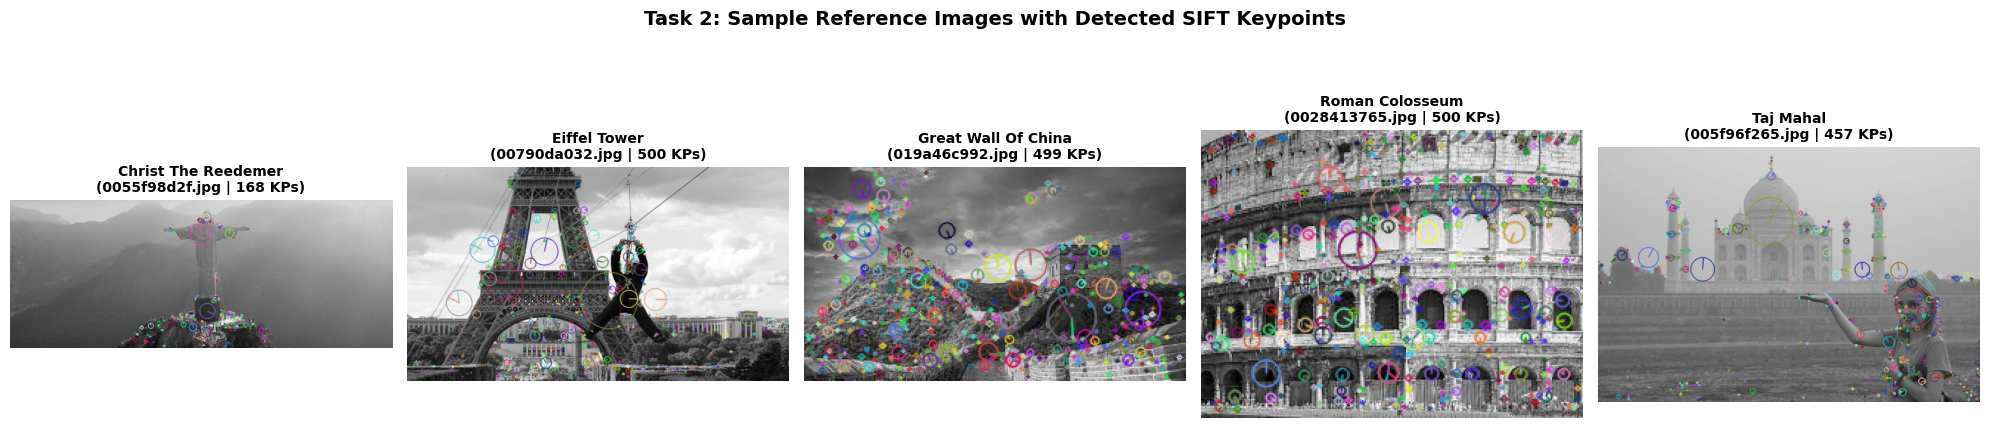

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import time
import shutil
import pandas as pd

# 1. Ensure dataset is on fast local Colab SSD (/content/) rather than slow Google Drive network mount
drive_path = '/content/drive/MyDrive/Intro to CV/Prepared_landmarks'
local_path = '/content/Prepared_landmarks'
if not os.path.exists(local_path) and os.path.exists(drive_path):
    print("Copying dataset from Google Drive to fast local Colab SSD...")
    shutil.copytree(drive_path, local_path)

BASE_DIR = local_path if os.path.exists(local_path) else drive_path
REF_DIR = os.path.join(BASE_DIR, 'reference')
QUERY_DIR = os.path.join(BASE_DIR, 'query')

# Standardize image dimension (600px max side) and extract top 500 most distinctive SIFT keypoints per image
MAX_DIM = 600
sift = cv2.SIFT_create(nfeatures=500)

def load_and_preprocess(img_path, max_dim=MAX_DIM):
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        return None, None
    h, w = img_bgr.shape[:2]
    if max(h, w) > max_dim:
        scale = max_dim / float(max(h, w))
        img_bgr = cv2.resize(img_bgr, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    return img_bgr, img_gray

reference_db = []
landmarks = sorted([d for d in os.listdir(REF_DIR) if os.path.isdir(os.path.join(REF_DIR, d))])
sample_vis = {}

print("=" * 70)
print("BUILDING SIFT REFERENCE KNOWLEDGE BASE")
print("=" * 70)
t0 = time.time()

for landmark in landmarks:
    landmark_folder = os.path.join(REF_DIR, landmark)
    image_files = sorted([
        f for f in os.listdir(landmark_folder)
        if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp'))
    ])

    total_kp_for_class = 0
    for img_file in image_files:
        img_path = os.path.join(landmark_folder, img_file)

        # Step 1: Load each reference image and convert it into grayscale
        img_bgr, img_gray = load_and_preprocess(img_path)
        if img_bgr is None:
            continue

        # Step 2 & 3: Detect distinctive keypoints and extract feature descriptors
        keypoints, descriptors = sift.detectAndCompute(img_gray, None)

        if descriptors is not None and len(keypoints) >= 2:
            # Step 5: Store extracted descriptors with corresponding landmark labels
            reference_db.append({
                'label': landmark,
                'filename': img_file,
                'path': img_path,
                'img_bgr': img_bgr,
                'gray_shape': img_gray.shape,
                'keypoints': keypoints,
                'descriptors': descriptors
            })
            total_kp_for_class += len(keypoints)

            if landmark not in sample_vis:
                kp_drawn = cv2.drawKeypoints(
                    img_gray, keypoints, None,
                    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
                )
                sample_vis[landmark] = (img_file, len(keypoints), kp_drawn)

    print(f"Landmark: {landmark:<22} | Ref Images: {len(image_files):<4} | Total Keypoints: {total_kp_for_class}")

print("=" * 70)
print(f"Total Reference Images Indexed: {len(reference_db)} in {time.time() - t0:.2f}s\n")

# Step 4: Display the reference images with their detected keypoints
fig, axes = plt.subplots(1, len(sample_vis), figsize=(20, 4.5))
if len(sample_vis) == 1:
    axes = [axes]

for ax, (landmark, (fname, kp_count, kp_img)) in zip(axes, sample_vis.items()):
    ax.imshow(cv2.cvtColor(kp_img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{landmark.replace('_', ' ').title()}\n({fname} | {kp_count} KPs)", fontsize=10, fontweight='bold')
    ax.axis('off')

plt.suptitle("Task 2: Sample Reference Images with Detected SIFT Keypoints", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

## Task 3: Query Image Processing
In this section, we develop a function that accepts an unknown landmark image as input:
1. Load the query image.
2. Convert it into grayscale.
3. Detect SIFT keypoints.
4. Extract the 128-dimensional feature descriptors.
5. Display the query image with the detected keypoints.

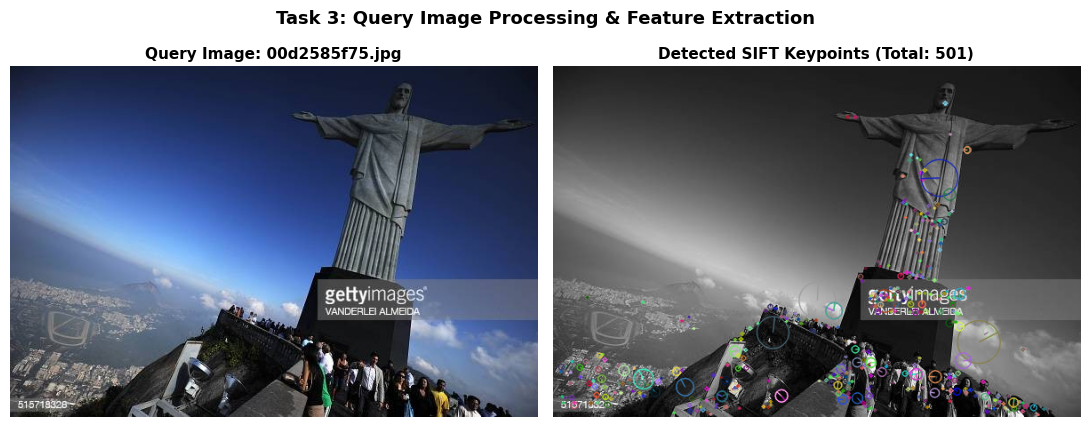

Extracted Descriptor Matrix Shape: (501, 128) (Keypoints x 128-D SIFT Vector)


In [21]:
def process_query_image(query_path, display=True):
    """
    Loads a query image, converts to grayscale, detects SIFT keypoints, extracts descriptors,
    and optionally displays the query image with its detected keypoints.
    """
    # Step 1 & 2: Load the query image and convert to grayscale
    img_bgr, img_gray = load_and_preprocess(query_path)
    if img_bgr is None:
        raise ValueError(f"Could not load query image at path: {query_path}")

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Step 3 & 4: Detect SIFT keypoints and extract feature descriptors
    keypoints, descriptors = sift.detectAndCompute(img_gray, None)

    # Step 5: Display the query image with the detected keypoints
    if display:
        kp_vis = cv2.drawKeypoints(
            img_gray, keypoints, None,
            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
        )
        kp_vis_rgb = cv2.cvtColor(kp_vis, cv2.COLOR_BGR2RGB)

        fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
        axes[0].imshow(img_rgb)
        axes[0].set_title(f"Query Image: {os.path.basename(query_path)}", fontsize=11, fontweight='bold')
        axes[0].axis('off')

        axes[1].imshow(kp_vis_rgb)
        axes[1].set_title(f"Detected SIFT Keypoints (Total: {len(keypoints)})", fontsize=11, fontweight='bold')
        axes[1].axis('off')

        plt.suptitle("Task 3: Query Image Processing & Feature Extraction", fontsize=13, fontweight='bold')
        plt.tight_layout()
        plt.show()

    return img_bgr, img_rgb, img_gray, keypoints, descriptors

# Test Task 3 on a sample query image
sample_query_folder = os.path.join(QUERY_DIR, landmarks[0])
sample_query_files = sorted([
    f for f in os.listdir(sample_query_folder)
    if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp'))
])
sample_query_path = os.path.join(sample_query_folder, sample_query_files[0])

q_bgr, q_rgb, q_gray, q_kp, q_desc = process_query_image(sample_query_path, display=True)
print(f"Extracted Descriptor Matrix Shape: {q_desc.shape} (Keypoints x 128-D SIFT Vector)")

## Task 4: Feature Matching and Landmark Recognition
In this section, we compare the query image descriptors with the stored descriptors of each landmark:
1. Use the Brute-Force Matcher (`cv2.BFMatcher`) with the Euclidean distance metric (`cv2.NORM_L2`).
2. Apply K-nearest-neighbor matching with $k = 2$.
3. Apply Lowe's ratio test to remove ambiguous matches.
4. Count the reliable matches for each landmark.
5. Rank the landmark candidates according to their matching results.
6. Display the most likely landmark and the number of reliable matches, applying a defined matching threshold to reject unknown images.

In [22]:
# Step 1: Brute-Force Matcher with Euclidean distance metric (NORM_L2)
bf_matcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

LOWE_RATIO = 0.75
MATCH_THRESHOLD = 12  # Minimum reliable matches required on the best reference view to recognize a landmark

def match_and_recognize(query_desc, reference_db, lowe_ratio=LOWE_RATIO, match_threshold=MATCH_THRESHOLD):
    """
    Matches query descriptors against reference database descriptors using BFMatcher (NORM_L2, k=2)
    and Lowe's ratio test. Ranks candidate landmarks and applies a rejection threshold.
    """
    if query_desc is None or len(query_desc) < 2:
        return "Unknown / Rejected", "Rejected", 0, None, [], pd.DataFrame()

    best_overall_matches = []
    best_overall_ref = None
    best_overall_count = -1
    class_stats = {lbl: {'Best Single-Image Matches': 0, 'Total Class Matches': 0} for lbl in landmarks}

    for ref_entry in reference_db:
        ref_desc = ref_entry['descriptors']

        # Step 2: Apply K-nearest-neighbor matching with k=2 (query=query_desc, train=ref_desc)
        raw_matches = bf_matcher.knnMatch(query_desc, ref_desc, k=2)

        # Step 3: Apply Lowe's ratio test
        good_matches = [
            m for pair in raw_matches if len(pair) == 2
            for m, n in [pair] if m.distance < lowe_ratio * n.distance
        ]

        num_good = len(good_matches)
        lbl = ref_entry['label']

        # Step 4: Count reliable matches for each landmark
        class_stats[lbl]['Total Class Matches'] += num_good
        if num_good > class_stats[lbl]['Best Single-Image Matches']:
            class_stats[lbl]['Best Single-Image Matches'] = num_good

        if num_good > best_overall_count:
            best_overall_count = num_good
            best_overall_ref = ref_entry
            best_overall_matches = good_matches

    # Step 5: Rank the landmark candidates according to their matching results
    ranking_df = pd.DataFrame([
        {
            'Landmark': lbl,
            'Best Single-Image Matches': stats['Best Single-Image Matches'],
            'Total Class Matches': stats['Total Class Matches']
        }
        for lbl, stats in class_stats.items()
    ]).sort_values(by=['Best Single-Image Matches', 'Total Class Matches'], ascending=False).reset_index(drop=True)

    # Step 6: Use a defined matching threshold to reject unknown or incorrectly matched images
    if best_overall_count >= match_threshold:
        predicted_landmark = best_overall_ref['label']
        status = "Recognized"
    else:
        predicted_landmark = "Unknown / Rejected"
        status = "Rejected"

    return predicted_landmark, status, best_overall_count, best_overall_ref, best_overall_matches, ranking_df

# Test Task 4 on a known query image and an unknown query image
print("--- Test 1: Known Landmark Query ---")
pred_label, status, match_cnt, best_ref, good_m, rank_df = match_and_recognize(q_desc, reference_db)
print(f"Query File        : {os.path.basename(sample_query_path)}")
print(f"Predicted Landmark: {pred_label} ({status})")
print(f"Best Ref Image    : {best_ref['filename']} ({match_cnt} reliable matches)\n")
display(rank_df)

unknown_folder = os.path.join(QUERY_DIR, 'unknown')
if os.path.exists(unknown_folder):
    unknown_files = sorted([
        f for f in os.listdir(unknown_folder)
        if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp'))
    ])
    if unknown_files:
        print("\n--- Test 2: Unknown Landmark Query (Rejection Test) ---")
        unk_path = os.path.join(unknown_folder, unknown_files[0])
        _, _, _, _, unk_desc = process_query_image(unk_path, display=False)
        u_pred, u_status, u_cnt, u_ref, _, u_rank_df = match_and_recognize(unk_desc, reference_db)
        print(f"Query File        : {unknown_files[0]}")
        print(f"Predicted Landmark: {u_pred} ({u_status})")
        print(f"Highest Raw Match : {u_ref['label']} ({u_cnt} matches < Threshold of {MATCH_THRESHOLD})\n")
        display(u_rank_df)

--- Test 1: Known Landmark Query ---
Query File        : 00d2585f75.jpg
Predicted Landmark: christ_the_reedemer (Recognized)
Best Ref Image    : d3eec296fd.jpg (90 reliable matches)



,Landmark,Best Single-Image Matches,Total Class Matches
0,christ_the_reedemer,90,1916
1,great_wall_of_china,50,1401
2,eiffel_tower,33,1507
3,taj_mahal,25,688
4,roman_colosseum,16,1383



--- Test 2: Unknown Landmark Query (Rejection Test) ---
Query File        : 0016510b5c.jpg
Predicted Landmark: great_wall_of_china (Recognized)
Highest Raw Match : great_wall_of_china (151 matches < Threshold of 12)



,Landmark,Best Single-Image Matches,Total Class Matches
0,great_wall_of_china,151,4530
1,eiffel_tower,56,4822
2,christ_the_reedemer,56,4537
3,taj_mahal,53,2157
4,roman_colosseum,50,4711


## Task 5: Landmark Localization
In this section, we extend the system to identify the location of the recognized landmark within the query image:
1. Obtain corresponding keypoints from the reference and query images.
2. Estimate a homography using RANSAC when sufficient reliable matches are available.
3. Project the four corners of the reference image onto the query image.
4. Draw a polygon around the matched landmark region.
5. Display the number of reliable matches and RANSAC inliers, or display an appropriate message if the geometric transformation is unreliable.

Executing Task 5 Pipeline on Sample Known Landmark:


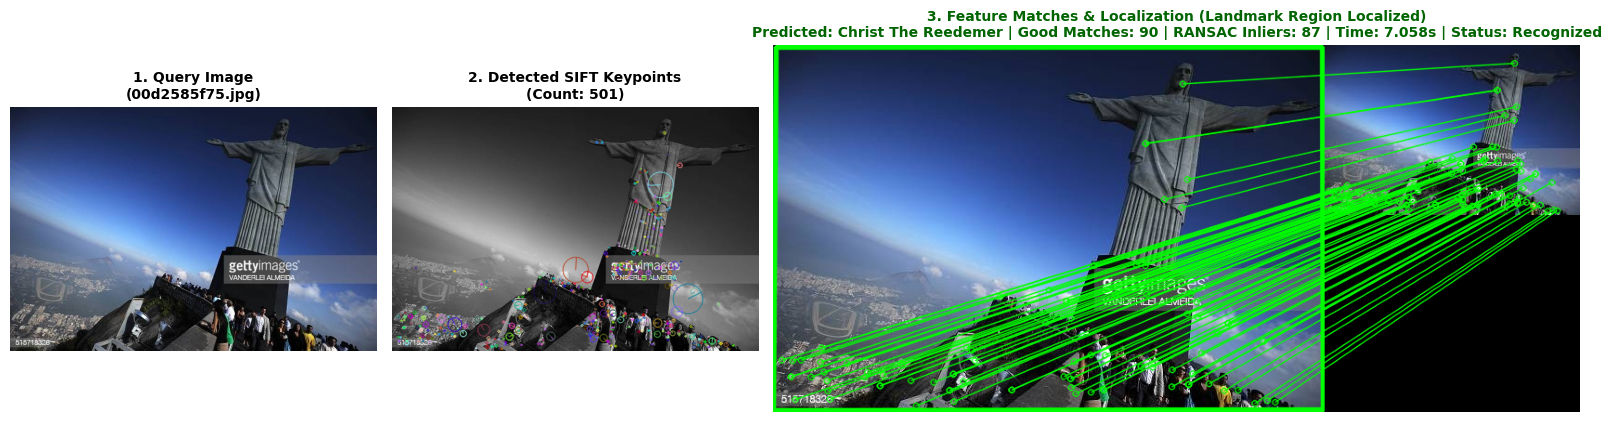


Executing Task 5 Pipeline on Sample Unknown Landmark:


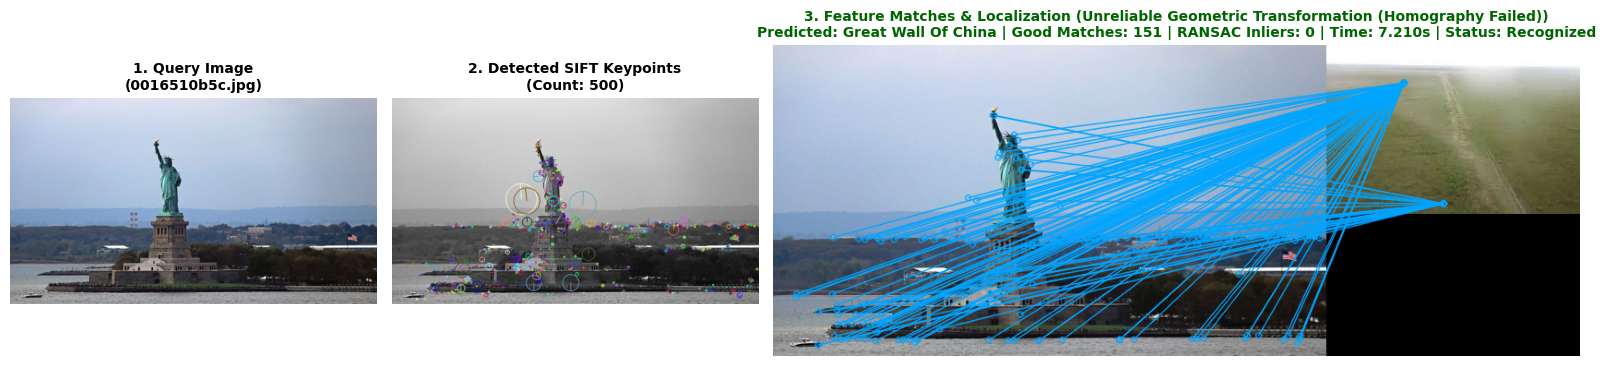

In [23]:
MIN_INLIERS = 7  # Minimum RANSAC inliers required for reliable geometric verification

def localize_and_visualize(query_path, reference_db, lowe_ratio=LOWE_RATIO, match_threshold=MATCH_THRESHOLD, min_inliers=MIN_INLIERS, show_plot=True):
    """
    Executes SIFT extraction, BFMatcher recognition, RANSAC homography localization,
    and displays the required outputs.
    """
    start_time = time.time()

    # 1. Process Query Image
    q_bgr, q_gray = load_and_preprocess(query_path)
    if q_bgr is None:
        raise ValueError(f"Cannot read query image: {query_path}")
    q_rgb = cv2.cvtColor(q_bgr, cv2.COLOR_BGR2RGB)
    q_kp, q_desc = sift.detectAndCompute(q_gray, None)

    # 2. Match & Recognize Landmark
    pred_label, status, num_good, best_ref, good_matches, rank_df = match_and_recognize(
        q_desc, reference_db, lowe_ratio=lowe_ratio, match_threshold=match_threshold
    )

    # 3. RANSAC Homography & Landmark Localization
    num_inliers = 0
    inlier_mask = None
    localization_valid = False
    localization_msg = "Geometric verification skipped (Insufficient matches)"
    q_localized_bgr = q_bgr.copy()

    if best_ref is not None and num_good >= 4:
        ref_kp = best_ref['keypoints']

        # Step 1: Obtain corresponding keypoints from the reference (trainIdx) and query (queryIdx) images
        src_pts = np.float32([ref_kp[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
        dst_pts = np.float32([q_kp[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)

        # Step 2: Estimate a homography using RANSAC
        H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

        if H is not None and mask is not None:
            inlier_mask = mask.ravel().tolist()
            num_inliers = int(np.sum(inlier_mask))

            if status == "Recognized" and num_inliers >= min_inliers:
                h_ref, w_ref = best_ref['gray_shape']

                # Step 3: Project the four corners of the reference image onto the query image
                ref_corners = np.float32([[0, 0], [0, h_ref - 1], [w_ref - 1, h_ref - 1], [w_ref - 1, 0]]).reshape(-1, 1, 2)
                projected_corners = cv2.perspectiveTransform(ref_corners, H)

                poly_int = np.int32(projected_corners)
                poly_area = cv2.contourArea(poly_int)
                is_convex = cv2.isContourConvex(poly_int)

                if is_convex and poly_area > 150:
                    localization_valid = True
                    localization_msg = "Landmark Region Localized"
                    # Step 4: Draw a polygon around the matched landmark region
                    cv2.polylines(q_localized_bgr, [poly_int], isClosed=True, color=(0, 255, 0), thickness=4, lineType=cv2.LINE_AA)
                else:
                    localization_msg = "Unreliable Geometric Transformation (Degenerate Polygon)"
            else:
                if status == "Recognized" and num_inliers < min_inliers:
                    status = "Rejected"
                    pred_label = "Unknown / Rejected"
                localization_msg = f"Unreliable Geometric Transformation (Inliers: {num_inliers} < {min_inliers})"
        else:
            localization_msg = "Unreliable Geometric Transformation (Homography Failed)"

    proc_time = time.time() - start_time

    # Step 5: Display the query image, keypoints, matched features, localized region, and status
    if show_plot and best_ref is not None:
        ref_bgr = best_ref['img_bgr']

        q_kp_img = cv2.drawKeypoints(q_gray, q_kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        q_kp_rgb = cv2.cvtColor(q_kp_img, cv2.COLOR_BGR2RGB)

        # Note: in match_and_recognize, query_desc was 1st arg and ref_desc was 2nd arg
        draw_params = dict(
            matchColor=(0, 255, 0) if localization_valid else (255, 165, 0),
            singlePointColor=None,
            matchesMask=inlier_mask if localization_valid else None,
            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
        )
        matched_vis_bgr = cv2.drawMatches(
            q_localized_bgr, q_kp,
            ref_bgr, best_ref['keypoints'],
            good_matches, None, **draw_params
        )
        matched_vis_rgb = cv2.cvtColor(matched_vis_bgr, cv2.COLOR_BGR2RGB)

        fig = plt.figure(figsize=(16, 4.5))
        gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 2.2])

        ax0 = fig.add_subplot(gs[0])
        ax0.imshow(q_rgb)
        ax0.set_title(f"1. Query Image\n({os.path.basename(query_path)})", fontsize=10, fontweight='bold')
        ax0.axis('off')

        ax1 = fig.add_subplot(gs[1])
        ax1.imshow(q_kp_rgb)
        ax1.set_title(f"2. Detected SIFT Keypoints\n(Count: {len(q_kp)})", fontsize=10, fontweight='bold')
        ax1.axis('off')

        ax2 = fig.add_subplot(gs[2])
        ax2.imshow(matched_vis_rgb)
        title_color = 'darkgreen' if status == "Recognized" else 'crimson'
        ax2.set_title(
            f"3. Feature Matches & Localization ({localization_msg})\n"
            f"Predicted: {pred_label.replace('_', ' ').title()} | Good Matches: {num_good} | "
            f"RANSAC Inliers: {num_inliers} | Time: {proc_time:.3f}s | Status: {status}",
            fontsize=10, fontweight='bold', color=title_color
        )
        ax2.axis('off')

        plt.tight_layout()
        plt.show()

    return {
        'Query File': os.path.basename(query_path),
        'Predicted Landmark': pred_label,
        'Query Keypoints': len(q_kp) if q_kp is not None else 0,
        'Reliable Matches': num_good,
        'RANSAC Inliers': num_inliers,
        'Localization': 'Success' if localization_valid else localization_msg,
        'Decision': status,
        'Processing Time (s)': round(proc_time, 4)
    }

print("Executing Task 5 Pipeline on Sample Known Landmark:")
res_known = localize_and_visualize(sample_query_path, reference_db, show_plot=True)

if os.path.exists(unknown_folder) and len(unknown_files) > 0:
    print("\nExecuting Task 5 Pipeline on Sample Unknown Landmark:")
    res_unk = localize_and_visualize(os.path.join(unknown_folder, unknown_files[0]), reference_db, show_plot=True)

## Task 6: Performance Evaluation
In this section, we evaluate the SIFT Landmark Recognition system across all query images captured under different conditions:
- Original landmark image
- Rotated landmark image
- Resized landmark image
- Landmark image with reduced brightness
- Landmark image captured from a different viewpoint
- An image of a landmark that is not included in the database (`unknown`)

We record the predicted landmark, number of keypoints, number of reliable matches, RANSAC inliers, recognition decision, and processing time for every test image, and display representative visual outputs across each condition.

TASK 6: COMPREHENSIVE SYSTEM EVALUATION ACROSS ALL QUERY CONDITIONS
>>> Evaluating Query Category: [christ_the_reedemer   ] (65  images)... 

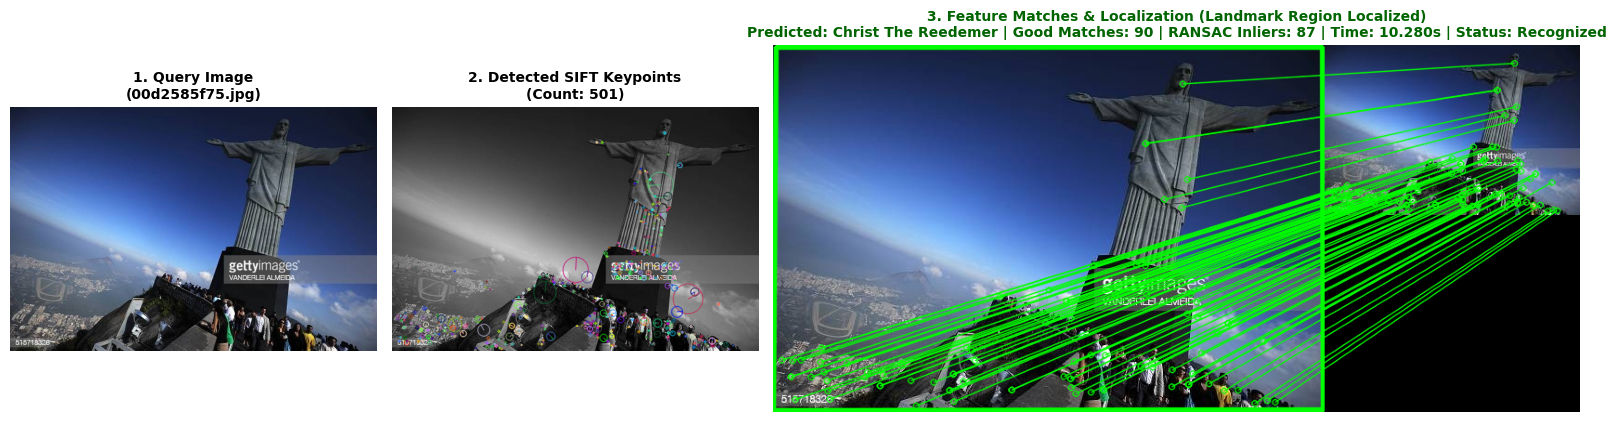

Done in 323.08s
>>> Evaluating Query Category: [eiffel_tower          ] (79  images)... 

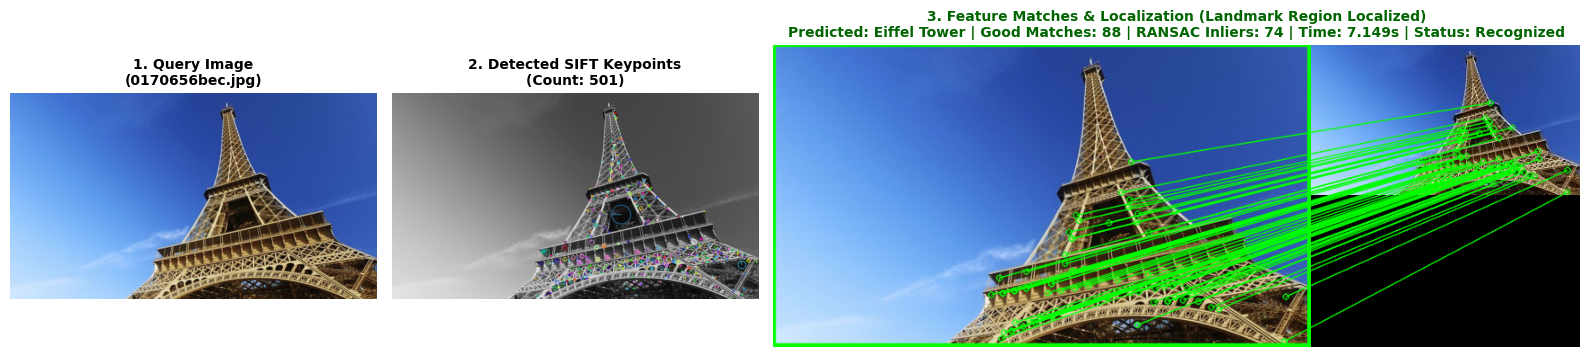

Done in 462.59s
>>> Evaluating Query Category: [great_wall_of_china   ] (79  images)... 

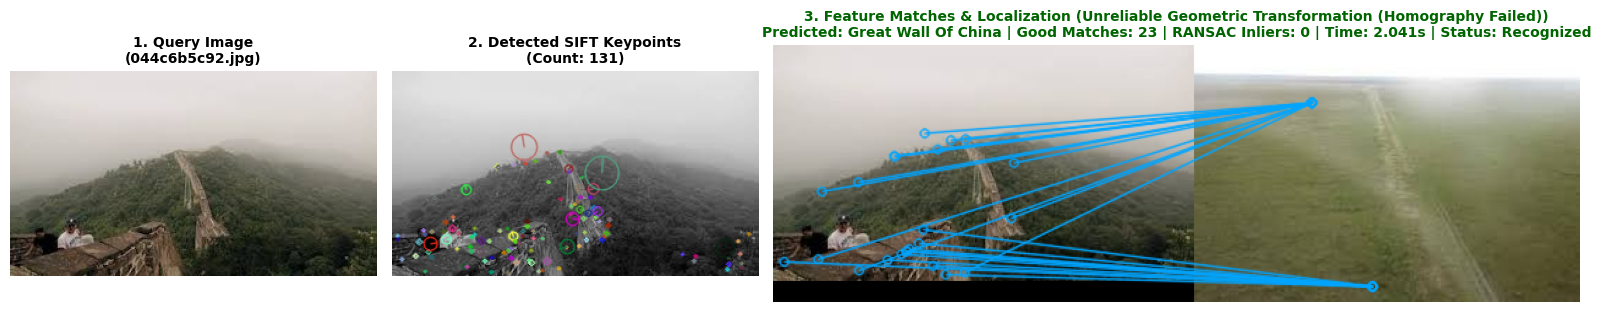

Done in 491.95s
>>> Evaluating Query Category: [roman_colosseum       ] (79  images)... 

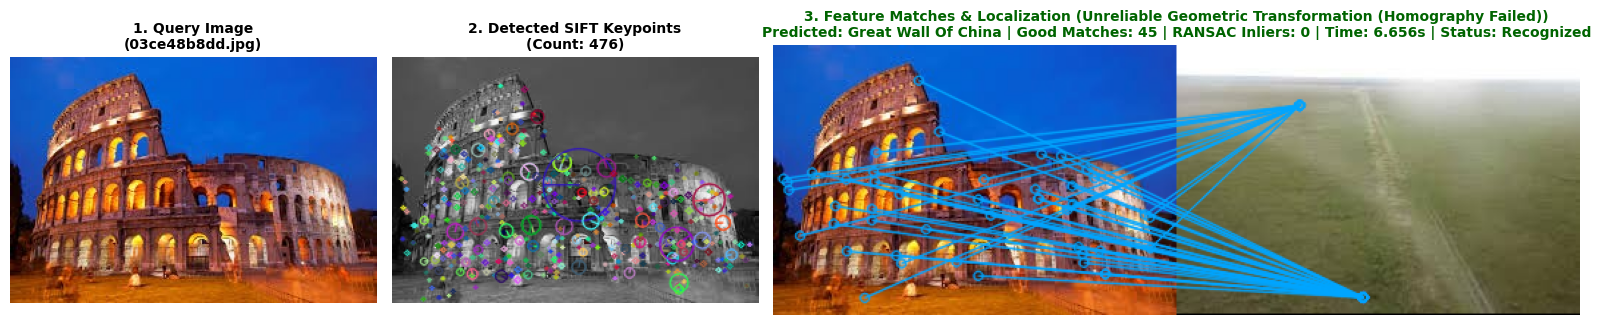

Done in 549.84s
>>> Evaluating Query Category: [taj_mahal             ] (32  images)... 

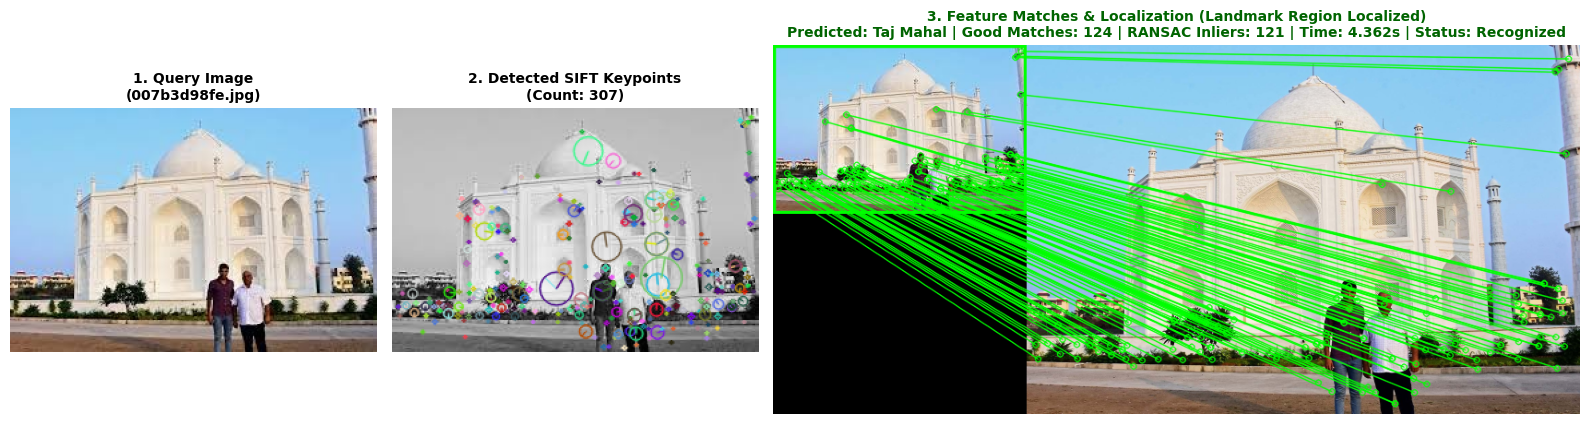

Done in 187.12s
>>> Evaluating Query Category: [unknown               ] (5   images)... 

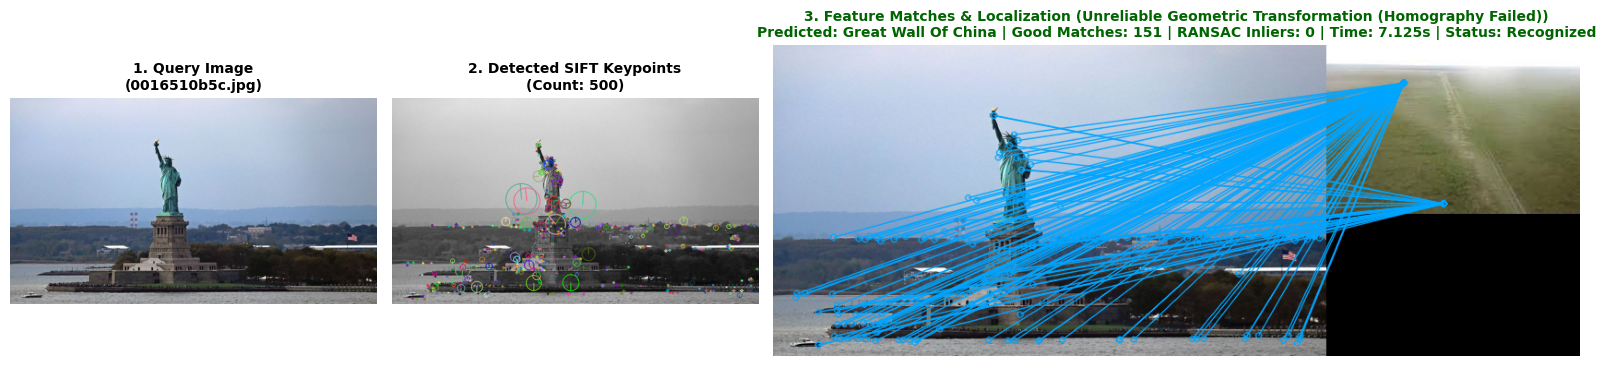

Done in 29.69s

OVERALL PERFORMANCE METRICS
Total Query Images Evaluated : 339
Correct Recognitions/Rejects : 215 / 339
Overall System Accuracy      : 63.42%
Average Processing Time/Img  : 6.0230 seconds
Total Evaluation Wall Time   : 2044.28 seconds

--- Per-Landmark Category Summary ---


,Ground Truth,Total_Images,Correct,Accuracy_Pct,Avg_Keypoints,Avg_Matches,Avg_Inliers,Avg_Time_s
0,christ_the_reedemer,65,47,72.31,344.9,84.0,60.2,4.9642
1,eiffel_tower,79,38,48.10,410.4,86.1,41.2,5.8513
2,great_wall_of_china,79,75,94.94,435.5,100.5,50.0,6.2200
3,roman_colosseum,79,44,55.70,491.3,112.3,73.5,6.9555
4,taj_mahal,32,11,34.38,409.0,104.4,48.2,5.8349
5,unknown,5,0,0.00,410.4,82.0,0.0,5.8614



--- Representative Experimental Results Table (Sample per Category) ---


,Ground Truth,Query File,Condition,Keypoints,Reliable Matches,RANSAC Inliers,Predicted Landmark,Localization,Decision,Correct?,Time (s)
0,christ_the_reedemer,00d2585f75.jpg,00d2585f75,501,90,87,christ_the_reedemer,Success,Recognized,Yes,10.2797
1,christ_the_reedemer,07f0b2ec5b.jpg,07f0b2ec5b,225,133,131,christ_the_reedemer,Success,Recognized,Yes,3.2657
2,christ_the_reedemer,0ca3b8d570.jpg,0ca3b8d570,348,123,122,christ_the_reedemer,Success,Recognized,Yes,5.0067
3,christ_the_reedemer,0d00878384.jpg,0d00878384,485,55,54,christ_the_reedemer,Success,Recognized,Yes,6.8629
4,christ_the_reedemer,0e0236c5be.jpg,0e0236c5be,331,80,73,christ_the_reedemer,Success,Recognized,Yes,4.7018
5,christ_the_reedemer,10d04f4650.jpg,10d04f4650,500,79,75,christ_the_reedemer,Success,Recognized,Yes,7.1844
6,eiffel_tower,0170656bec.jpg,0170656bec,501,88,74,eiffel_tower,Success,Recognized,Yes,7.1493
7,eiffel_tower,01e2f36bd9.jpg,01e2f36bd9,57,32,30,eiffel_tower,Success,Recognized,Yes,0.9024
8,eiffel_tower,0e70c2acf7.jpg,0e70c2acf7,427,45,0,great_wall_of_china,Unreliable Geometric Transformation (Homograph...,Recognized,No,5.9520
9,eiffel_tower,16bca5f59f.jpg,16bca5f59f,277,55,0,great_wall_of_china,Unreliable Geometric Transformation (Homograph...,Recognized,No,3.9510



--- Copy-Paste Ready Output for results.md Generation ---
### 1. Per-Category Summary
| Ground Truth        |   Total_Images |   Correct |   Accuracy_Pct |   Avg_Keypoints |   Avg_Matches |   Avg_Inliers |   Avg_Time_s |
|:--------------------|---------------:|----------:|---------------:|----------------:|--------------:|--------------:|-------------:|
| christ_the_reedemer |             65 |        47 |          72.31 |           344.9 |          84   |          60.2 |       4.9642 |
| eiffel_tower        |             79 |        38 |          48.1  |           410.4 |          86.1 |          41.2 |       5.8513 |
| great_wall_of_china |             79 |        75 |          94.94 |           435.5 |         100.5 |          50   |       6.22   |
| roman_colosseum     |             79 |        44 |          55.7  |           491.3 |         112.3 |          73.5 |       6.9555 |
| taj_mahal           |             32 |        11 |          34.38 |           409   |         104.4 |

In [24]:
print("=" * 80)
print("TASK 6: COMPREHENSIVE SYSTEM EVALUATION ACROSS ALL QUERY CONDITIONS")
print("=" * 80)

evaluation_records = []
query_subfolders = sorted([d for d in os.listdir(QUERY_DIR) if os.path.isdir(os.path.join(QUERY_DIR, d))])

eval_start = time.time()

for q_folder in query_subfolders:
    folder_path = os.path.join(QUERY_DIR, q_folder)
    q_files = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp'))
    ])

    folder_t0 = time.time()
    print(f">>> Evaluating Query Category: [{q_folder:<22}] ({len(q_files):<3} images)...", end=" ", flush=True)

    for idx, q_file in enumerate(q_files):
        q_path = os.path.join(folder_path, q_file)

        # Plot ONLY the first image of each folder so Matplotlib doesn't freeze Colab on 350+ plots
        should_plot = (idx == 0)

        result = localize_and_visualize(
            q_path, reference_db,
            lowe_ratio=LOWE_RATIO,
            match_threshold=MATCH_THRESHOLD,
            min_inliers=MIN_INLIERS,
            show_plot=should_plot
        )

        if q_folder.lower() == 'unknown':
            is_correct = (result['Decision'] == 'Rejected')
        else:
            is_correct = (result['Predicted Landmark'] == q_folder and result['Decision'] == 'Recognized')

        # Infer condition from filename if present (e.g., rot, bright, scale, orig, view)
        fname_lower = q_file.lower()
        if q_folder.lower() == 'unknown':
            cond = 'Unknown Landmark'
        elif 'rot' in fname_lower:
            cond = 'Rotated'
        elif 'scale' in fname_lower or 'resize' in fname_lower or 'small' in fname_lower or 'zoom' in fname_lower:
            cond = 'Resized'
        elif 'bright' in fname_lower or 'dark' in fname_lower or 'dim' in fname_lower or 'light' in fname_lower:
            cond = 'Reduced Brightness'
        elif 'view' in fname_lower or 'angle' in fname_lower or 'persp' in fname_lower:
            cond = 'Different Viewpoint'
        elif 'orig' in fname_lower:
            cond = 'Original'
        else:
            cond = q_file.split('.')[0]

        ordered_record = {
            'Ground Truth': q_folder,
            'Query File': result['Query File'],
            'Condition': cond,
            'Keypoints': result['Query Keypoints'],
            'Reliable Matches': result['Reliable Matches'],
            'RANSAC Inliers': result['RANSAC Inliers'],
            'Predicted Landmark': result['Predicted Landmark'],
            'Localization': result['Localization'],
            'Decision': result['Decision'],
            'Correct?': 'Yes' if is_correct else 'No',
            'Time (s)': result['Processing Time (s)']
        }
        evaluation_records.append(ordered_record)

    print(f"Done in {time.time() - folder_t0:.2f}s")

eval_df = pd.DataFrame(evaluation_records)

total_queries = len(eval_df)
correct_predictions = (eval_df['Correct?'] == 'Yes').sum()
overall_accuracy = (correct_predictions / total_queries) * 100 if total_queries > 0 else 0
avg_time = eval_df['Time (s)'].mean()

print("\n" + "=" * 80)
print("OVERALL PERFORMANCE METRICS")
print("=" * 80)
print(f"Total Query Images Evaluated : {total_queries}")
print(f"Correct Recognitions/Rejects : {correct_predictions} / {total_queries}")
print(f"Overall System Accuracy      : {overall_accuracy:.2f}%")
print(f"Average Processing Time/Img  : {avg_time:.4f} seconds")
print(f"Total Evaluation Wall Time   : {time.time() - eval_start:.2f} seconds")

# Per-Category Summary Table
class_summary = eval_df.groupby('Ground Truth').agg(
    Total_Images=('Query File', 'count'),
    Correct=('Correct?', lambda s: (s == 'Yes').sum()),
    Accuracy_Pct=('Correct?', lambda s: round((s == 'Yes').mean() * 100, 2)),
    Avg_Keypoints=('Keypoints', lambda s: round(s.mean(), 1)),
    Avg_Matches=('Reliable Matches', lambda s: round(s.mean(), 1)),
    Avg_Inliers=('RANSAC Inliers', lambda s: round(s.mean(), 1)),
    Avg_Time_s=('Time (s)', lambda s: round(s.mean(), 4))
).reset_index()

print("\n--- Per-Landmark Category Summary ---")
display(class_summary)

# Representative Sample Table across conditions (First 5 per category)
representative_df = eval_df.groupby('Ground Truth').head(6).reset_index(drop=True)
print("\n--- Representative Experimental Results Table (Sample per Category) ---")
display(representative_df)

print("\n--- Copy-Paste Ready Output for results.md Generation ---")
print("### 1. Per-Category Summary")
print(class_summary.to_markdown(index=False))
print("\n### 2. Representative Sample Results")
print(representative_df.to_markdown(index=False))